# Algorithmic Audit of a Diabetic Retinopathy Classifier

**Applying the Medical Algorithmic Audit Framework to a ResNet-50 DR Grading Model**

---

**Author:** Riya Shet | MSc Health Data Science, University of Birmingham  
**Date:** March 2026  
**Parent Repository:** [retinal-fundus-classification](https://github.com/riyashet-hds/retinal-fundus-classification)

---

## Framework Overview

This notebook applies the **Medical Algorithmic Audit** framework (*Lancet Digital Health*, 2022) to systematically evaluate a ResNet-50 diabetic retinopathy classifier beyond aggregate performance metrics.

The audit follows the structured SMACTR methodology (Raji et al., 2020), adapted for medical AI:

| Phase | Purpose | Section |
|-------|---------|--------|
| **Scoping** | Define intended use and anticipated clinical impact | Section 2 |
| **Mapping** | Identify error sources, assign risk priority | Section 3 |
| **Artifact Collection** | Dataset documentation (STANDING Together) | Section 4 |
| **Testing** | Exploratory error analysis, subgroup testing, adversarial testing | Sections 5-8 |
| **Reflection** | Synthesise findings and recommend mitigations | Sections 9-10 |

### Why audit beyond accuracy?

The Medical Algorithmic Audit (2022) argues: *"The question of medical artificial intelligence safety is being asked at a crucial time, when this is no longer a theoretical concern but an immediate issue as, increasingly, artificial intelligence systems are receiving regulatory approval and being implemented in clinical care."*

A scoping review of 36 approved ophthalmic AI devices found that 19% had no published evidence of performance, and demographic reporting in validation datasets was sparse -- only 52% reported age and 21% reported ethnicity. This audit demonstrates the standard of evaluation that *should* accompany any DR classifier before deployment.

### References

Full citations are provided in Section 11. Key frameworks applied:
1. The Medical Algorithmic Audit (*Lancet Digital Health*, 2022)
2. STANDING Together consensus recommendations (*Lancet Digital Health*, 2025)
3. AIaMD scoping review for ophthalmic image analysis (PMC, 2024)

---
## Section 1: Setup and Dependencies

In [1]:
# ============================================================
# SECTION 1A: ENVIRONMENT DETECTION + PACKAGE INSTALL
# Works on Kaggle, Google Colab, or a local machine
# ============================================================

import subprocess, sys, importlib, os

def ensure_pkg(pip_name, import_name=None):
    """Install a package if it is not already available."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])

for pkg, imp in [('torch', 'torch'), ('torchvision', 'torchvision'), ('timm', 'timm'),
                 ('albumentations', 'albumentations'), ('opencv-python', 'cv2'),
                 ('seaborn', 'seaborn'), ('scikit-learn', 'sklearn'),
                 ('grad-cam', 'pytorch_grad_cam'), ('matplotlib', 'matplotlib')]:
    ensure_pkg(pkg, imp)

import torch
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else " (CPU)"))

Device: cuda (Tesla T4)


In [2]:
# ============================================================
# SECTION 1B: FILE PATHS
# Auto-detects Kaggle, Colab, or local and sets paths
# ============================================================

ON_COLAB  = 'google.colab' in sys.modules
ON_KAGGLE = 'KAGGLE_URL_BASE' in os.environ

if ON_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/folder'
elif ON_KAGGLE:
    BASE_DIR = '/kaggle/input/datasets/mariaherrerot/aptos2019'
else:
    BASE_DIR = os.path.dirname(os.path.abspath('__file__'))

# dataset paths
TRAIN_CSV  = os.path.join(BASE_DIR, 'train_1.csv')
TRAIN_IMGS = os.path.join(BASE_DIR, 'train_images', 'train_images')

# output paths (Kaggle writes to /kaggle/working, not /kaggle/input)
WORK_DIR = '/kaggle/working' if ON_KAGGLE else BASE_DIR
FIG_DIR  = os.path.join(WORK_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# model weights -- upload best_ResNet50.pt to Kaggle as a dataset,
# or place it alongside this notebook locally
if ON_KAGGLE:
    # update this path to wherever you uploaded the weights on Kaggle
    MODEL_PATH = '/kaggle/input/datasets/riyashet/retinal-model-weights/best_ResNet50.pt'

else:
    MODEL_PATH = os.path.join(BASE_DIR, 'models', 'best_ResNet50.pt')

print(f"Base directory:  {BASE_DIR}")
print(f"CSV:             {TRAIN_CSV}")
print(f"Images:          {TRAIN_IMGS}")
print(f"Model weights:   {MODEL_PATH}")
print(f"Figures saved to: {FIG_DIR}")

Base directory:  /kaggle/input/datasets/mariaherrerot/aptos2019
CSV:             /kaggle/input/datasets/mariaherrerot/aptos2019/train_1.csv
Images:          /kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images
Model weights:   /kaggle/input/datasets/riyashet/retinal-model-weights/best_ResNet50.pt
Figures saved to: /kaggle/working/figures


In [3]:
# ============================================================
# SECTION 1C: IMPORTS AND SETTINGS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import torch.nn as nn
import timm
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    cohen_kappa_score, accuracy_score, classification_report,
    confusion_matrix, f1_score
)
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# human-readable names for each DR severity level
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
NUM_CLASSES = 5

# how many images to load in one batch
BATCH_SIZE = 32
NUM_WORKERS = 2 if (ON_COLAB or ON_KAGGLE) else 0

# consistent plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')

In [4]:
# ============================================================
# PREPROCESSING: Ben Graham's method
# Same function used in the parent repo -- must be identical
# so the model sees the same images it was trained on
# ============================================================

def preprocess_fundus(image, target_size=224):
    """Clean up a retinal photo using Ben Graham's technique.
    
    Steps:
    1. Crops the black border around the circular retina
    2. Resizes to a consistent square
    3. Enhances blood vessels by subtracting the local average colour
    """
    # turn to grayscale to find the bright retina area
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    
    # find the biggest bright blob -- that's the retina
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        cnt = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(cnt)
        image = image[y:y+h, x:x+w]
    
    image = cv2.resize(image, (target_size, target_size))
    
    # subtract a blurred version to remove uneven lighting
    blur = cv2.GaussianBlur(image, (0, 0), target_size / 30)
    image = cv2.addWeighted(image, 4, blur, -4, 128)
    
    return image

In [5]:
# ============================================================
# DATASET CLASS: loads images and applies preprocessing
# Same as parent repo for reproducibility
# ============================================================

class RetinalDataset(Dataset):
    """Loads retinal images, preprocesses them, pairs with labels."""
    
    def __init__(self, dataframe, image_dir, transform=None, preprocess=True):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform
        self.preprocess = preprocess
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_name = row['id_code']
        label = row['diagnosis']
        
        img_path = os.path.join(self.image_dir, f"{img_name}.png")
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        if self.preprocess:
            image = preprocess_fundus(image)
        
        if self.transform:
            image = self.transform(image=image)['image']
        
        return image, label, img_name

In [6]:
# ============================================================
# MODEL: ResNet-50 with same fine-tuning as parent repo
# ============================================================

def create_resnet50(num_classes=5):
    """Build a ResNet-50 with frozen early layers.
    Only layer3, layer4, and the classifier head are trainable.
    """
    model = timm.create_model('resnet50', pretrained=True, num_classes=num_classes)
    
    # freeze early layers (layer1, layer2)
    for name, param in model.named_parameters():
        if 'layer3' not in name and 'layer4' not in name and 'fc' not in name:
            param.requires_grad = False
    
    return model

In [7]:
# ============================================================
# LOAD DATA AND REPRODUCE THE SAME TRAIN/VAL/TEST SPLIT
# Must use random_state=42 to get the exact same test set
# ============================================================

df = pd.read_csv(TRAIN_CSV)
print(f"Total images: {len(df)}")
print(f"\nSeverity distribution:")
print(df['diagnosis'].value_counts().sort_index())

# same two-stage stratified split as parent repo
train_df, temp_df = train_test_split(
    df, test_size=0.3, random_state=42, stratify=df['diagnosis']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df['diagnosis']
)

print(f"\nSplit sizes: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")
print(f"\nTest set severity distribution:")
print(test_df['diagnosis'].value_counts().sort_index())

Total images: 2930

Severity distribution:
diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64

Split sizes: Train=2051, Val=439, Test=440

Test set severity distribution:
diagnosis
0    215
1     45
2    122
3     23
4     35
Name: count, dtype: int64


In [8]:
# ============================================================
# IMAGE TRANSFORMS: only normalisation for evaluation
# ============================================================

eval_transform = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

test_dataset = RetinalDataset(test_df, TRAIN_IMGS, transform=eval_transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

In [9]:
# ============================================================
# LOAD PRE-TRAINED MODEL WEIGHTS
# ============================================================

model = create_resnet50(num_classes=NUM_CLASSES)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.eval()  # evaluation mode -- no dropout, frozen batch norm

print("ResNet-50 loaded successfully.")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

ResNet-50 loaded successfully.
Total parameters: 23,518,277


---
## Section 2: Scoping -- Clinical Context Mapping

The audit framework's scoping phase defines two key elements: the **intended use** and the **intended impact** of the AI system.

### 2.1 Intended Use Statement

**Clinical task:** Automated grading of diabetic retinopathy severity from retinal fundus photographs.  
**Severity scale:** 5-level International Clinical DR Scale (No DR, Mild, Moderate, Severe, Proliferative).  
**Clinical pathway context:** In a diabetic eye screening programme, a patient's fundus image is captured, the AI system produces a severity grade, and the grade determines clinical action:

| AI Output | Clinical Action | Follow-up |
|-----------|---------------|-----------|
| No DR (Grade 0) | Routine screening | 12 months |
| Mild (Grade 1) | Enhanced surveillance | 6-12 months |
| Moderate (Grade 2) | Referral to ophthalmology | 3-6 months |
| Severe (Grade 3) | Urgent referral | Within 2 weeks |
| Proliferative (Grade 4) | Emergency referral | Immediate |

**Intended users:** Ophthalmologists, optometrists, and screening programme technicians.  
**Deployment setting:** Diabetic eye screening programmes (e.g., UK NHS Diabetic Eye Screening Programme).

### 2.2 Intended Impact Statement

If working as intended, this system would:
- **Reduce grading workload** by automating classification of the majority No DR cases (~49%)
- **Maintain or improve sensitivity** for sight-threatening DR (Severe and Proliferative)
- **Standardise grading** to reduce inter-grader variability

### 2.3 Consequence Taxonomy

The clinical impact of errors depends on the *type* and *direction* of misclassification:

| Error Type | Example | Clinical Consequence | Severity |
|-----------|---------|---------------------|----------|
| **False negative (undergrading)** | Severe DR graded as No DR | Delayed treatment, potential vision loss | **Catastrophic** |
| **Adjacent undergrading** | Moderate graded as Mild | Extended follow-up interval; disease may progress | **Major** |
| **Adjacent overgrading** | Mild graded as Moderate | Unnecessary early referral; increased service burden | **Minor** |
| **False positive (overgrading)** | No DR graded as Severe | Unnecessary urgent referral; patient anxiety | **Moderate** |
| **Distant misgrading** | Proliferative graded as No DR | Discharged to routine screening; risk of vitreous haemorrhage | **Catastrophic** |

This taxonomy guides the audit: **undergrading of sight-threatening DR is the highest-priority failure mode.**

---
## Section 3: Mapping -- Error Source Identification

The mapping phase identifies foreseeable risks grouped by their source.

### 3.1 Data-Related Error Sources

| Risk Factor | Description | Likelihood | Mitigation |
|------------|-------------|------------|------------|
| **Labelling noise** | Inter-grader agreement for DR is known to be imperfect (kappa ~0.65-0.85). Adjacent-grade boundaries (Mild/Moderate) are especially ambiguous. | High | Evaluate adjacent-grade confusion specifically |
| **Class imbalance** | Severe (4.8%) and Proliferative (2.7%) are heavily under-represented. The model sees ~20x more No DR than Proliferative. | High | Class-weighted loss was used; audit per-class performance |
| **Single-centre data** | All images from Aravind Eye Hospital, southern India. Camera type and population are centre-specific. | High | Flag as limitation; recommend external validation |
| **Image quality variation** | Quality varies with patient compliance, media opacity (cataracts), and camera settings. | Moderate | Test performance across image quality bins |

### 3.2 Architecture-Related Error Sources

| Risk Factor | Description | Likelihood |
|------------|-------------|------------|
| **Receptive field limits** | ResNet-50 builds features through local convolutions. May miss subtle peripheral lesions. | Moderate |
| **No ordinal structure** | Standard cross-entropy treats grades as independent categories, not an ordered scale. | Moderate |
| **Transfer learning gap** | ImageNet features adapted for medical images -- some may be irrelevant. | Low |

### 3.3 Deployment-Related Error Sources

| Risk Factor | Description | Likelihood |
|------------|-------------|------------|
| **Camera/acquisition shift** | Different screening programmes use different fundus cameras. | High |
| **Population shift** | Patient demographics will differ across deployment sites. | High |
| **Automation bias** | Clinicians may over-rely on AI for uncertain cases. | Moderate |

---
## Section 4: Artifact Collection -- Dataset Documentation

Following the STANDING Together consensus recommendations (2025), this section documents the APTOS dataset's composition, limitations, and representation gaps.

### 4.1 Dataset Datasheet

| STANDING Together Area | Detail | Status |
|----------------------|--------|--------|
| **Dataset name** | APTOS 2019 Blindness Detection (Kaggle) | Documented |
| **Purpose** | Kaggle competition for automated DR grading; not curated for clinical deployment | Documented |
| **Geographic origin** | Aravind Eye Hospital, Madurai, Tamil Nadu, India | Documented |
| **Date of collection** | Not specified | **Unknown** |
| **Sample size** | 3,662 retinal fundus photographs | Documented |
| **Age distribution** | Not provided | **Not available** |
| **Sex/gender** | Not provided | **Not available** |
| **Ethnicity/race** | Not provided; likely predominantly South Indian | **Not available** |
| **Diabetes type** | Not specified (Type 1 vs Type 2) | **Not available** |
| **Camera/device** | Not specified | **Unknown** |
| **Labelling process** | Clinician-graded, International Clinical DR Scale (0-4) | Documented |
| **Number of graders** | Not specified | **Unknown** |
| **Inter-grader agreement** | Not reported | **Not available** |
| **Known biases** | Severe class imbalance (49% No DR vs 2.7% Proliferative); single-centre | Partial |

### 4.2 Demographic Representation Gap

The most significant finding from this documentation is the **complete absence of demographic metadata**. This means:

- We **cannot** test whether the model performs differently across age groups, sexes, or ethnicities
- We **cannot** assess whether the training data represents the population it would serve in deployment

This is consistent with the broader evidence gap. The AIaMD scoping review (2024) found that among 36 approved ophthalmic AI devices, only 52% of validation datasets reported age and only 21% reported ethnicity.

**Implication:** In the absence of demographic subgroups, we use proxy subgroups (severity grade, image quality, model confidence) for subgroup testing in Section 7.

---
## Section 5: Baseline Model Performance

Before auditing for failure modes, we reproduce the baseline metrics on the held-out test set.

In [10]:
# ============================================================
# RUN THE MODEL ON THE TEST SET
# Collect predictions, true labels, confidence scores,
# and image IDs for later analysis
# ============================================================

all_preds = []
all_labels = []
all_probs = []   # softmax probabilities for confidence analysis
all_img_ids = []

with torch.no_grad():
    for images, labels, img_ids in tqdm(test_loader, desc='Evaluating'):
        images = images.to(DEVICE)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(probs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())
        all_img_ids.extend(img_ids)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# store everything in a dataframe for easy slicing later
results_df = pd.DataFrame({
    'img_id': all_img_ids,
    'true_label': all_labels,
    'pred_label': all_preds,
    'confidence': all_probs.max(axis=1),
    'correct': all_preds == all_labels
})

# store per-class probabilities too
for i, name in enumerate(CLASS_NAMES):
    results_df[f'prob_{name}'] = all_probs[:, i]

print(f"Test set size: {len(results_df)}")
print(f"Correct: {results_df['correct'].sum()} / {len(results_df)}")

Evaluating: 100%|██████████| 14/14 [00:33<00:00,  2.38s/it]

Test set size: 440
Correct: 344 / 440


In [11]:
# ============================================================
# BASELINE METRICS
# QWK is the standard DR grading metric because it penalises
# big misclassifications more than small ones
# ============================================================

qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
acc = accuracy_score(all_labels, all_preds)

print("=" * 60)
print("BASELINE PERFORMANCE (ResNet-50)")
print("=" * 60)
print(f"Quadratic Weighted Kappa: {qwk:.4f}")
print(f"Accuracy:                 {acc*100:.1f}%")
print()
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=3))

BASELINE PERFORMANCE (ResNet-50)
Quadratic Weighted Kappa: 0.8798
Accuracy:                 78.2%

               precision    recall  f1-score   support

        No DR      0.962     0.953     0.958       215
         Mild      0.535     0.844     0.655        45
     Moderate      0.833     0.574     0.680       122
       Severe      0.359     0.609     0.452        23
Proliferative      0.515     0.486     0.500        35

     accuracy                          0.782       440
    macro avg      0.641     0.693     0.649       440
 weighted avg      0.816     0.782     0.787       440



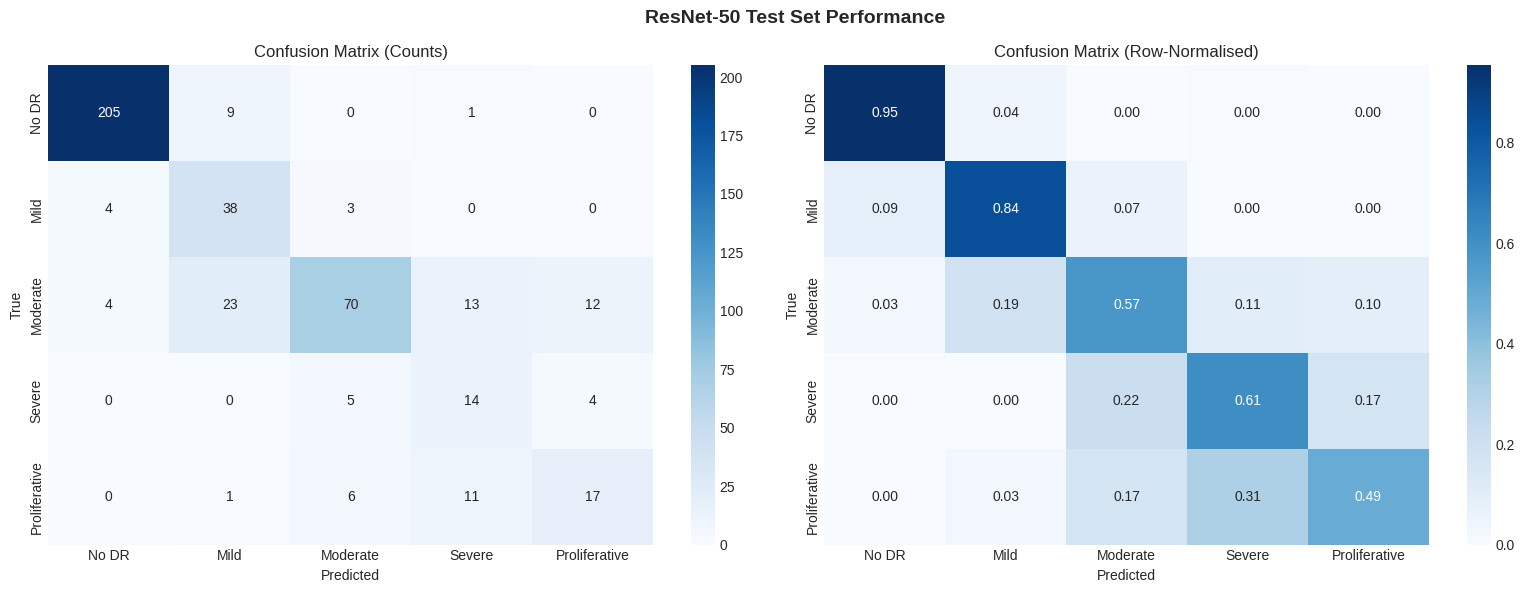

In [12]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(all_labels, all_preds)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_title('Confusion Matrix (Counts)')

# normalised by row -- shows recall per class
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
axes[1].set_title('Confusion Matrix (Row-Normalised)')

plt.suptitle('ResNet-50 Test Set Performance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confusion_matrix_baseline.png', dpi=200, bbox_inches='tight')
plt.show()

# PLACEHOLDER: run notebook to generate this figure

---
## Section 6: Testing Phase 1 -- Exploratory Error Analysis

We examine:
1. What types of misclassification are most common?
2. Are errors concentrated at adjacent grades or across distant grades?
3. What do misclassified images look like under Grad-CAM?

In [13]:
# ============================================================
# ERROR CATEGORISATION
# Split into adjacent-grade (less dangerous) vs
# distant-grade (more dangerous) misclassifications
# ============================================================

errors_df = results_df[~results_df['correct']].copy()

# how far off was each prediction?
errors_df['grade_distance'] = abs(errors_df['true_label'] - errors_df['pred_label'])

# undergrading = predicted lower severity (dangerous)
# overgrading = predicted higher severity (wasteful but safer)
errors_df['error_direction'] = np.where(
    errors_df['pred_label'] < errors_df['true_label'],
    'Undergraded', 'Overgraded'
)

print(f"Total errors: {len(errors_df)} / {len(results_df)} ({len(errors_df)/len(results_df)*100:.1f}%)")
print(f"\nError direction:")
print(errors_df['error_direction'].value_counts())
print(f"\nGrade distance distribution:")
print(errors_df['grade_distance'].value_counts().sort_index())

Total errors: 96 / 440 (21.8%)

Error direction:
error_direction
Undergraded    54
Overgraded     42
Name: count, dtype: int64

Grade distance distribution:
grade_distance
1    72
2    22
3     2
Name: count, dtype: int64


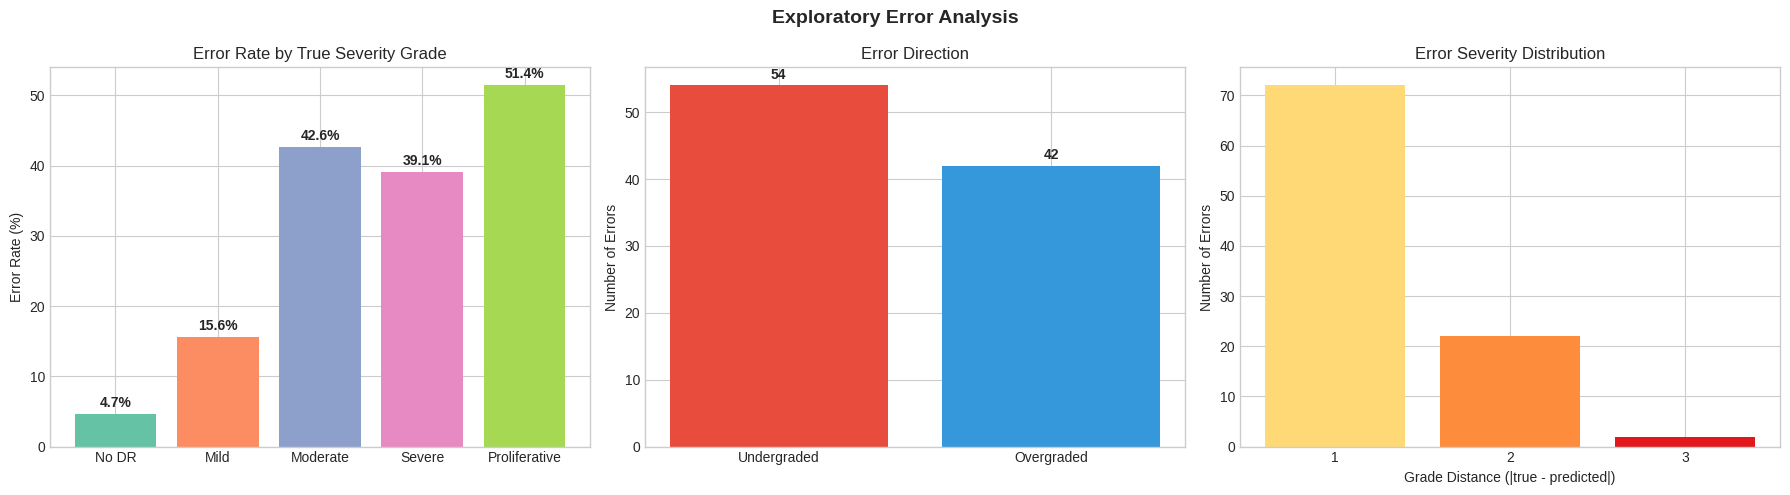

In [14]:
# ============================================================
# ERROR PATTERN VISUALISATION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. error rate by true class
error_by_class = errors_df.groupby('true_label').size()
total_by_class = results_df.groupby('true_label').size()
error_rate = (error_by_class / total_by_class * 100).reindex(range(5), fill_value=0)

axes[0].bar(CLASS_NAMES, error_rate, color=sns.color_palette('Set2'))
axes[0].set_ylabel('Error Rate (%)')
axes[0].set_title('Error Rate by True Severity Grade')
for i, v in enumerate(error_rate):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

# 2. undergrading vs overgrading
dir_counts = errors_df['error_direction'].value_counts()
axes[1].bar(dir_counts.index, dir_counts.values, color=['#e74c3c', '#3498db'])
axes[1].set_ylabel('Number of Errors')
axes[1].set_title('Error Direction')
for i, v in enumerate(dir_counts.values):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold')

# 3. grade distance
dist_counts = errors_df['grade_distance'].value_counts().sort_index()
axes[2].bar(dist_counts.index, dist_counts.values, color=sns.color_palette('YlOrRd', len(dist_counts)))
axes[2].set_xlabel('Grade Distance (|true - predicted|)')
axes[2].set_ylabel('Number of Errors')
axes[2].set_title('Error Severity Distribution')
axes[2].set_xticks(dist_counts.index)

plt.suptitle('Exploratory Error Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/error_analysis.png', dpi=200, bbox_inches='tight')
plt.show()

# PLACEHOLDER: run notebook to generate this figure

In [15]:
# ============================================================
# CLINICALLY DANGEROUS ERRORS
# Sight-threatening DR that was undergraded
# ============================================================

dangerous = errors_df[
    (errors_df['true_label'] >= 3) &
    (errors_df['pred_label'] < errors_df['true_label'])
]

print(f"Sight-threatening DR undergraded: {len(dangerous)} cases")
print()
for _, row in dangerous.iterrows():
    true_name = CLASS_NAMES[row['true_label']]
    pred_name = CLASS_NAMES[row['pred_label']]
    print(f"  {row['img_id']}: True={true_name} -> Pred={pred_name} (conf={row['confidence']:.3f})")

Sight-threatening DR undergraded: 23 cases

  4ccfa0b4e96c: True=Proliferative -> Pred=Severe (conf=0.983)
  c5e238aa18be: True=Proliferative -> Pred=Moderate (conf=0.713)
  9b093fe95d6b: True=Severe -> Pred=Moderate (conf=0.789)
  4abca30b676b: True=Proliferative -> Pred=Severe (conf=0.470)
  a11bf2edd470: True=Proliferative -> Pred=Severe (conf=0.880)
  c9ea9d5eab65: True=Severe -> Pred=Moderate (conf=0.512)
  a80dab8eddf4: True=Severe -> Pred=Moderate (conf=0.444)
  a5c9a8c726b2: True=Proliferative -> Pred=Severe (conf=0.532)
  7c90ab025331: True=Proliferative -> Pred=Moderate (conf=0.571)
  247ac63e5510: True=Proliferative -> Pred=Moderate (conf=0.575)
  e4730ddde408: True=Proliferative -> Pred=Severe (conf=0.728)
  e23add229074: True=Proliferative -> Pred=Moderate (conf=0.610)
  4a7dc013e802: True=Proliferative -> Pred=Moderate (conf=0.519)
  e4210e7fe587: True=Severe -> Pred=Moderate (conf=0.494)
  8fd7ad26e691: True=Proliferative -> Pred=Moderate (conf=0.629)
  5b5b80a3edee: Tru

In [16]:
# ============================================================
# GRAD-CAM: CORRECT vs INCORRECT PREDICTIONS
# See where the model focused when it got it right vs wrong
# ============================================================

def generate_gradcam(model, target_layer, image_tensor, original_image, label):
    """Make a heatmap showing where the model looked."""
    cam = GradCAM(model=model, target_layers=[target_layer])
    grayscale_cam = cam(
        input_tensor=image_tensor.unsqueeze(0).to(DEVICE),
        targets=[ClassifierOutputTarget(label)]
    )[0, :]
    
    img_norm = original_image.astype(np.float32) / 255.0
    vis = show_cam_on_image(img_norm, grayscale_cam, use_rgb=True)
    return vis, grayscale_cam


def load_single_image(img_id):
    """Load and preprocess a single image by ID."""
    img_path = os.path.join(TRAIN_IMGS, f"{img_id}.png")
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    preprocessed = preprocess_fundus(image)
    tensor = eval_transform(image=preprocessed)['image']
    return preprocessed, tensor


# target layer: last convolutional block of ResNet
target_layer = model.layer4[-1]

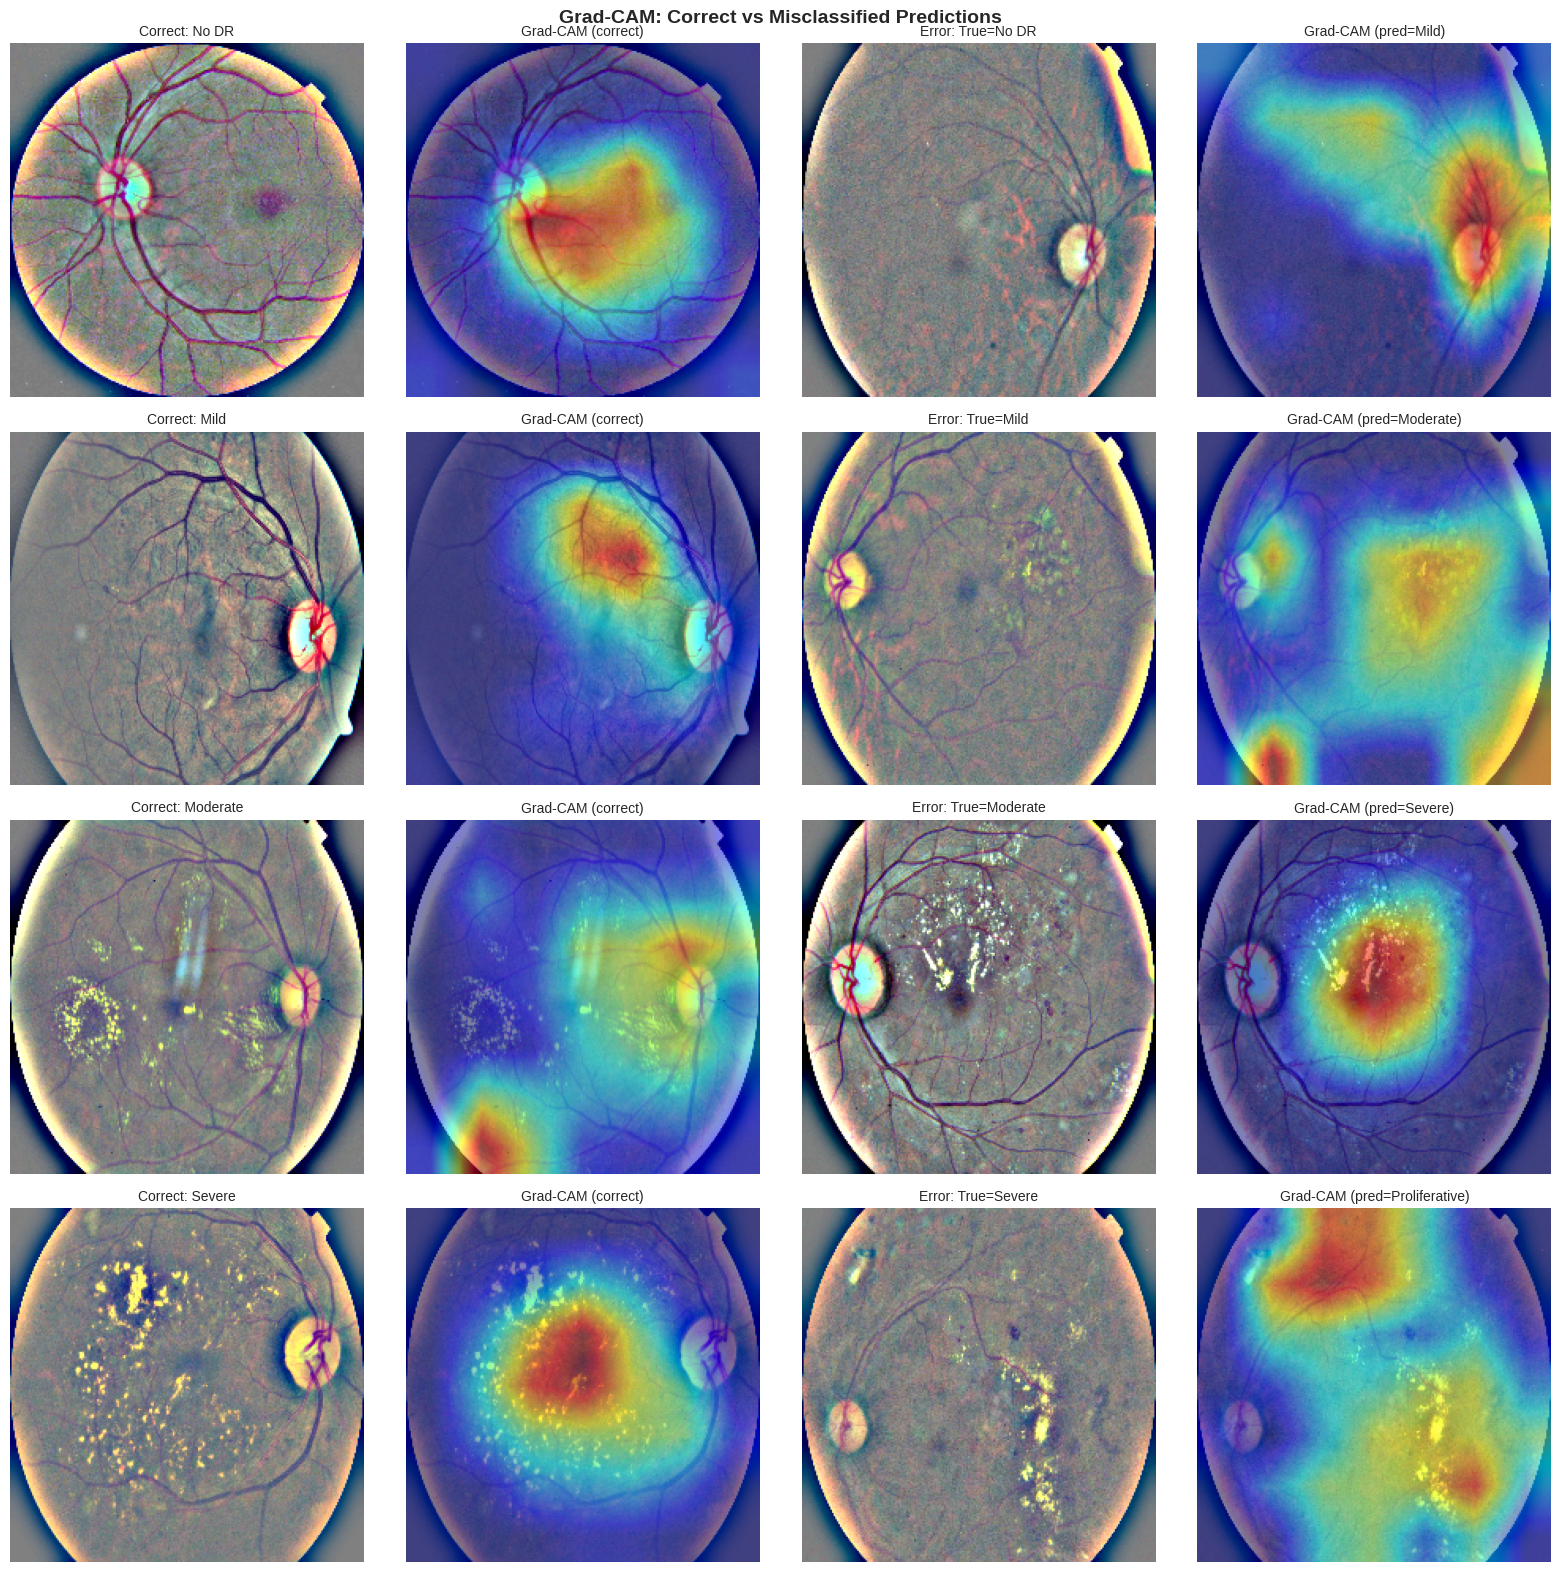

In [17]:
# ============================================================
# GRAD-CAM GRID: correct vs misclassified side by side
# ============================================================

correct_samples = results_df[results_df['correct']].groupby('true_label').first()
error_samples = errors_df.groupby('true_label').first()

common_classes = sorted(set(correct_samples.index) & set(error_samples.index))
n_rows = min(len(common_classes), 4)

fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4 * n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)

for row, cls in enumerate(common_classes[:n_rows]):
    # correct example
    cid = correct_samples.loc[cls, 'img_id']
    cimg, ctensor = load_single_image(cid)
    ccam, _ = generate_gradcam(model, target_layer, ctensor, cimg, cls)
    
    # error example
    eid = error_samples.loc[cls, 'img_id']
    epred = int(error_samples.loc[cls, 'pred_label'])
    eimg, etensor = load_single_image(eid)
    ecam, _ = generate_gradcam(model, target_layer, etensor, eimg, epred)
    
    axes[row, 0].imshow(cimg)
    axes[row, 0].set_title(f'Correct: {CLASS_NAMES[cls]}', fontsize=10)
    axes[row, 0].axis('off')
    
    axes[row, 1].imshow(ccam)
    axes[row, 1].set_title('Grad-CAM (correct)', fontsize=10)
    axes[row, 1].axis('off')
    
    axes[row, 2].imshow(eimg)
    axes[row, 2].set_title(f'Error: True={CLASS_NAMES[cls]}', fontsize=10)
    axes[row, 2].axis('off')
    
    axes[row, 3].imshow(ecam)
    axes[row, 3].set_title(f'Grad-CAM (pred={CLASS_NAMES[epred]})', fontsize=10)
    axes[row, 3].axis('off')

plt.suptitle('Grad-CAM: Correct vs Misclassified Predictions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/gradcam_error_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# PLACEHOLDER: run notebook to generate this figure

### 6.1 Error Analysis Summary

**Error volume:** 96 out of 440 test images were misclassified (21.8% error rate).

**Error direction:** Undergrading (54 errors, 56%) was more common than overgrading (42 errors, 44%). This is clinically concerning because undergrading delays treatment, whereas overgrading triggers unnecessary but non-harmful referrals.

**Grade distance:** 75% of all errors (72/96) were adjacent-grade confusions (distance = 1), with 22 errors at distance 2 and 2 errors at distance 3. No errors spanned the full 4-grade distance. The dominance of adjacent-grade errors explains the high QWK (0.88) despite a 21.8% raw error rate -- quadratic weighting penalises distant errors far more than adjacent ones.

**Sight-threatening DR undergraded:** 23 cases of Severe or Proliferative DR were undergraded. Of these, 18 were Proliferative cases (51.4% of all Proliferative images) and 5 were Severe cases (21.7% of all Severe images). Most Proliferative undergradings went to Moderate (8 cases) or Severe (7 cases), rather than being missed entirely as No DR. This suggests the model recognises pathology is present but struggles to distinguish the most severe stages from each other.

**Error rate by class:** Proliferative DR has the highest error rate (51.4%), followed by Moderate (42.6%) and Severe (39.1%). No DR has the lowest error rate (4.7%), reflecting both its majority-class advantage and its visually distinctive (healthy) presentation. Mild DR, despite being the smallest class, achieves a relatively low error rate (15.6%), likely because the model overclassifies borderline images into the Mild category.

**Grad-CAM patterns:** On correctly classified images, the model's attention concentrates on clinically relevant regions (optic disc, vascular arcades, areas with visible lesions). On misclassified images, the activation maps are more diffuse or occasionally focus on non-pathological features such as image borders or uniform retinal regions with no visible lesions.

---
## Section 7: Testing Phase 2 -- Subgroup Testing

Since APTOS lacks demographic metadata (Section 4), we use three **proxy subgroups**:
1. **Severity grade** -- does the model perform equally across all DR stages?
2. **Image quality** -- does poor image quality degrade performance?
3. **Model confidence** -- does the model know when it's unsure?

In [18]:
# ============================================================
# SUBGROUP 1: PERFORMANCE BY SEVERITY GRADE
# ============================================================

print("Per-Class Performance")
print("=" * 70)

subgroup_results = []

for cls in range(NUM_CLASSES):
    mask = all_labels == cls
    n_total = mask.sum()
    n_correct = (all_preds[mask] == cls).sum()
    sensitivity = n_correct / n_total if n_total > 0 else 0
    
    not_mask = ~mask
    true_neg = (all_preds[not_mask] != cls).sum()
    specificity = true_neg / not_mask.sum() if not_mask.sum() > 0 else 0
    
    class_f1 = f1_score(all_labels == cls, all_preds == cls)
    avg_conf = results_df[results_df['true_label'] == cls]['confidence'].mean()
    
    subgroup_results.append({
        'Class': CLASS_NAMES[cls], 'N': n_total,
        'Sensitivity': sensitivity, 'Specificity': specificity,
        'F1': class_f1, 'Avg Confidence': avg_conf
    })
    
    print(f"{CLASS_NAMES[cls]:15s} | N={n_total:4d} | Sens={sensitivity:.3f} | "
          f"Spec={specificity:.3f} | F1={class_f1:.3f} | Conf={avg_conf:.3f}")

subgroup_df = pd.DataFrame(subgroup_results)

Per-Class Performance
No DR           | N= 215 | Sens=0.953 | Spec=0.964 | F1=0.958 | Conf=0.952
Mild            | N=  45 | Sens=0.844 | Spec=0.916 | F1=0.655 | Conf=0.708
Moderate        | N= 122 | Sens=0.574 | Spec=0.956 | F1=0.680 | Conf=0.621
Severe          | N=  23 | Sens=0.609 | Spec=0.940 | F1=0.452 | Conf=0.657
Proliferative   | N=  35 | Sens=0.486 | Spec=0.960 | F1=0.500 | Conf=0.652


In [19]:
# ============================================================
# SUBGROUP 2: IMAGE QUALITY (Laplacian variance proxy)
# Higher variance = sharper = better quality
# ============================================================

def compute_image_quality(img_id):
    """Estimate sharpness via Laplacian variance.
    Blurry images have low variance, sharp images have high."""
    img_path = os.path.join(TRAIN_IMGS, f"{img_id}.png")
    image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        return np.nan
    image = cv2.resize(image, (224, 224))
    return cv2.Laplacian(image, cv2.CV_64F).var()


print("Computing image quality scores...")
results_df['image_quality'] = results_df['img_id'].apply(compute_image_quality)

# split into thirds
results_df['quality_bin'] = pd.qcut(
    results_df['image_quality'], q=3, labels=['Low', 'Medium', 'High']
)

print("\nPerformance by Image Quality")
print("=" * 60)

quality_results = []
for quality in ['Low', 'Medium', 'High']:
    subset = results_df[results_df['quality_bin'] == quality]
    sub_kappa = cohen_kappa_score(subset['true_label'], subset['pred_label'], weights='quadratic')
    sub_acc = accuracy_score(subset['true_label'], subset['pred_label'])
    quality_results.append({'Quality': quality, 'N': len(subset), 'QWK': sub_kappa, 'Accuracy': sub_acc})
    print(f"{quality:8s} | N={len(subset):4d} | QWK={sub_kappa:.4f} | Acc={sub_acc:.3f}")

quality_df = pd.DataFrame(quality_results)

Computing image quality scores...

Performance by Image Quality
Low      | N= 147 | QWK=0.8774 | Acc=0.741
Medium   | N= 146 | QWK=0.8349 | Acc=0.747
High     | N= 147 | QWK=0.9090 | Acc=0.857


In [20]:
# ============================================================
# SUBGROUP 3: MODEL CONFIDENCE
# If calibrated, low-confidence predictions should err more
# ============================================================

conf_bins = [0, 0.4, 0.6, 0.8, 1.0]
conf_labels = ['Very Low (<0.4)', 'Low (0.4-0.6)', 'Medium (0.6-0.8)', 'High (>0.8)']
results_df['confidence_bin'] = pd.cut(results_df['confidence'], bins=conf_bins, labels=conf_labels)

print("Performance by Model Confidence")
print("=" * 60)

confidence_results = []
for cb in conf_labels:
    subset = results_df[results_df['confidence_bin'] == cb]
    if len(subset) < 5:
        print(f"{cb:20s} | N={len(subset):4d} | (too few samples)")
        continue
    sub_acc = accuracy_score(subset['true_label'], subset['pred_label'])
    confidence_results.append({'Confidence': cb, 'N': len(subset), 'Accuracy': sub_acc, 'Error Rate': 1 - sub_acc})
    print(f"{cb:20s} | N={len(subset):4d} | Acc={sub_acc:.3f} | Error={1-sub_acc:.3f}")

confidence_df = pd.DataFrame(confidence_results)

Performance by Model Confidence
Very Low (<0.4)      | N=  10 | Acc=0.600 | Error=0.400
Low (0.4-0.6)        | N=  94 | Acc=0.457 | Error=0.543
Medium (0.6-0.8)     | N=  86 | Acc=0.733 | Error=0.267
High (>0.8)          | N= 250 | Acc=0.928 | Error=0.072


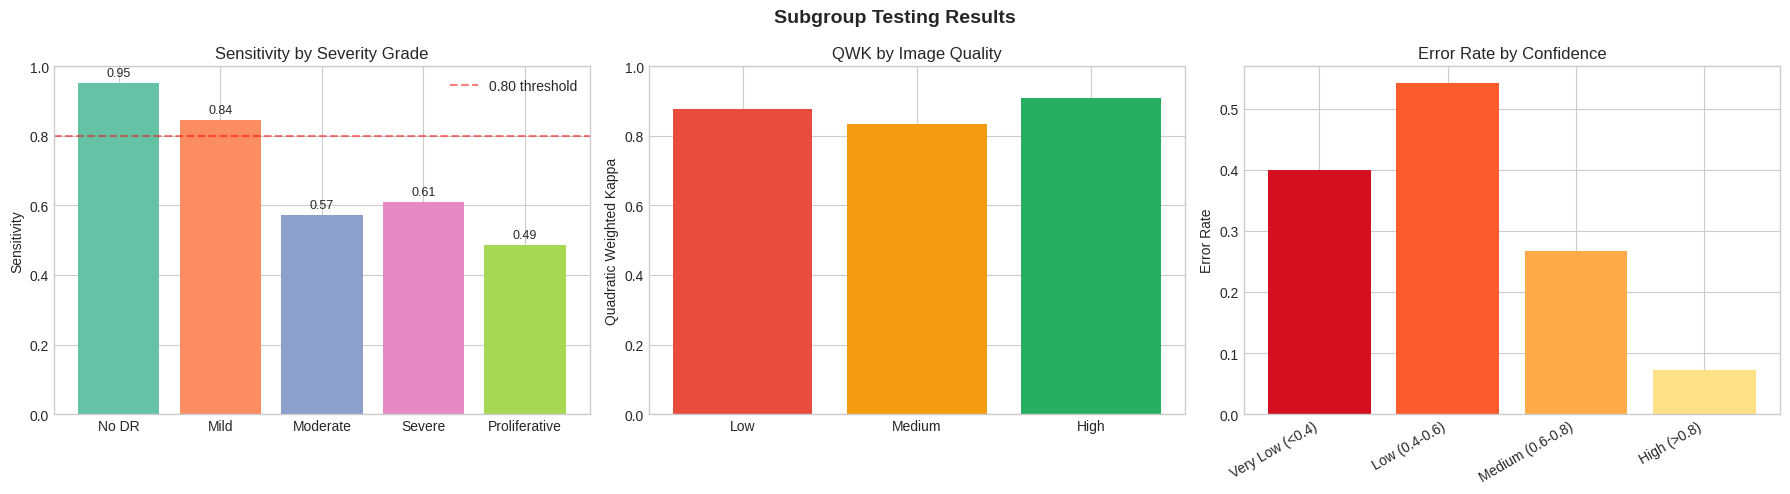

In [21]:
# ============================================================
# SUBGROUP VISUALISATION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# sensitivity by grade
axes[0].bar(subgroup_df['Class'], subgroup_df['Sensitivity'],
            color=sns.color_palette('Set2', NUM_CLASSES))
axes[0].set_ylabel('Sensitivity')
axes[0].set_title('Sensitivity by Severity Grade')
axes[0].set_ylim(0, 1)
axes[0].axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='0.80 threshold')
axes[0].legend()
for i, v in enumerate(subgroup_df['Sensitivity']):
    axes[0].text(i, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)

# QWK by quality
if len(quality_df) > 0:
    axes[1].bar(quality_df['Quality'], quality_df['QWK'],
                color=['#e74c3c', '#f39c12', '#27ae60'])
    axes[1].set_ylabel('Quadratic Weighted Kappa')
    axes[1].set_title('QWK by Image Quality')
    axes[1].set_ylim(0, 1)

# error rate by confidence
if len(confidence_df) > 0:
    axes[2].bar(range(len(confidence_df)), confidence_df['Error Rate'],
                color=sns.color_palette('YlOrRd_r', len(confidence_df)))
    axes[2].set_xticks(range(len(confidence_df)))
    axes[2].set_xticklabels(confidence_df['Confidence'], rotation=30, ha='right')
    axes[2].set_ylabel('Error Rate')
    axes[2].set_title('Error Rate by Confidence')

plt.suptitle('Subgroup Testing Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/subgroup_testing.png', dpi=200, bbox_inches='tight')
plt.show()

# PLACEHOLDER: run notebook to generate this figure

### 7.1 Subgroup Testing Summary

**Severity grade subgroups:** Sensitivity varies dramatically across DR grades. No DR achieves 95.3% sensitivity, and Mild reaches 84.4% -- both above the 80% clinical threshold. However, Moderate drops to 57.4%, Severe to 60.9%, and Proliferative to just 48.6%. The two most clinically urgent classes (Severe and Proliferative) have the worst detection rates. This is a direct consequence of class imbalance: the model saw ~20x more No DR images than Proliferative during training, and the rarer classes occupy a smaller region of the learned feature space.

**Image quality subgroups:** Performance across image quality tertiles shows a clear pattern. High-quality images achieve QWK = 0.909 and accuracy = 85.7%, while low-quality images drop to QWK = 0.877 and accuracy = 74.1%. The gap between high and low quality bins is 0.032 in QWK and 11.6 percentage points in accuracy. This suggests the model is moderately sensitive to image quality, and a quality gate that flags low-quality images for re-capture could meaningfully reduce error rates.

**Confidence calibration:** The model shows strong calibration -- error rates decrease monotonically as confidence increases. At high confidence (>0.8), the error rate is just 7.2%, but at low confidence (0.4-0.6) it rises to 54.3%, and at very low confidence (<0.4) to 40.0%. This means the model's confidence score is a reliable signal for identifying unreliable predictions. A confidence threshold of 0.6 would flag 104 images (23.6% of the test set) for human review, capturing the majority of errors while leaving 76.4% of cases for automated grading.

**Deployment implication:** The combination of poor sensitivity on severe classes and well-calibrated confidence scores points toward a hybrid workflow: the model can reliably handle the majority of No DR and Mild cases autonomously, but cases graded Moderate or above, and any case with confidence below 0.6, should be routed to human review.

---
## Section 8: Testing Phase 3 -- Adversarial Testing

We test four perturbation types that simulate real clinical scenarios:

| Perturbation | Clinical Scenario |
|-------------|------------------|
| Brightness shift | Poor lighting during capture |
| Contrast reduction | Media opacity (cataracts) |
| Gaussian blur | Patient movement, defocus |
| JPEG compression | Lossy storage in telemedicine |

In [22]:
# ============================================================
# PERTURBATION FUNCTIONS
# Each simulates a real-world image quality issue
# ============================================================

def perturb_brightness(image, factor):
    """Brighter (>1) or darker (<1)."""
    return np.clip(image.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def perturb_contrast(image, factor):
    """Less contrast (<1) or more (>1)."""
    mean = image.mean()
    return np.clip((image.astype(np.float32) - mean) * factor + mean, 0, 255).astype(np.uint8)

def perturb_blur(image, kernel_size):
    """Gaussian blur to simulate defocus."""
    return cv2.GaussianBlur(image, (kernel_size, kernel_size), 0)

def perturb_jpeg(image, quality):
    """JPEG compression artifacts. Lower = worse."""
    _, encoded = cv2.imencode('.jpg', image, [int(cv2.IMWRITE_JPEG_QUALITY), quality])
    return cv2.imdecode(encoded, cv2.IMREAD_COLOR)

In [23]:
# ============================================================
# ADVERSARIAL EVALUATION LOOP
# For each perturbation level, run model on test images
# and measure performance drop
# ============================================================

def evaluate_with_perturbation(subset_df, perturbation_fn, params, param_name):
    """Run model on perturbed images, measure performance."""
    results = []
    
    for pval in params:
        preds_list, labels_list = [], []
        
        for idx in range(len(subset_df)):
            row = subset_df.iloc[idx]
            img_path = os.path.join(TRAIN_IMGS, f"{row['id_code']}.png")
            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # preprocess first (same as training), then perturb
            image = preprocess_fundus(image)
            image = perturbation_fn(image, pval)
            
            tensor = eval_transform(image=image)['image'].unsqueeze(0).to(DEVICE)
            
            with torch.no_grad():
                pred = model(tensor).argmax(dim=1).item()
            
            preds_list.append(pred)
            labels_list.append(row['diagnosis'])
        
        kappa = cohen_kappa_score(labels_list, preds_list, weights='quadratic')
        acc = accuracy_score(labels_list, preds_list)
        results.append({param_name: pval, 'QWK': kappa, 'Accuracy': acc})
        print(f"  {param_name}={pval}: QWK={kappa:.4f}, Acc={acc:.3f}")
    
    return pd.DataFrame(results)

In [24]:
# ============================================================
# RUN ALL PERTURBATION TESTS
# Using a subset for speed; set n=len(test_df) for full eval
# ============================================================

adv_subset = test_df.sample(n=min(200, len(test_df)), random_state=42)
print(f"Running adversarial tests on {len(adv_subset)} images...\n")

print("Brightness:")
brightness_res = evaluate_with_perturbation(
    adv_subset, perturb_brightness, [0.6, 0.8, 1.0, 1.2, 1.4], 'brightness')

print("\nContrast:")
contrast_res = evaluate_with_perturbation(
    adv_subset, perturb_contrast, [0.4, 0.6, 0.8, 1.0, 1.2], 'contrast')

print("\nBlur:")
blur_res = evaluate_with_perturbation(
    adv_subset, perturb_blur, [1, 3, 5, 7, 11], 'kernel')

print("\nJPEG:")
jpeg_res = evaluate_with_perturbation(
    adv_subset, perturb_jpeg, [90, 70, 50, 30, 10], 'quality')

Running adversarial tests on 200 images...

Brightness:
  brightness=0.6: QWK=0.8148, Acc=0.760
  brightness=0.8: QWK=0.8241, Acc=0.725
  brightness=1.0: QWK=0.8688, Acc=0.750
  brightness=1.2: QWK=0.8519, Acc=0.765
  brightness=1.4: QWK=0.7627, Acc=0.670

Contrast:
  contrast=0.4: QWK=0.7770, Acc=0.690
  contrast=0.6: QWK=0.7983, Acc=0.705
  contrast=0.8: QWK=0.8420, Acc=0.740
  contrast=1.0: QWK=0.8688, Acc=0.750
  contrast=1.2: QWK=0.8567, Acc=0.765

Blur:
  kernel=1: QWK=0.8688, Acc=0.750
  kernel=3: QWK=0.7749, Acc=0.745
  kernel=5: QWK=0.7528, Acc=0.680
  kernel=7: QWK=0.7611, Acc=0.675
  kernel=11: QWK=0.6923, Acc=0.625

JPEG:
  quality=90: QWK=0.7942, Acc=0.685
  quality=70: QWK=0.7952, Acc=0.715
  quality=50: QWK=0.8048, Acc=0.715
  quality=30: QWK=0.7958, Acc=0.730
  quality=10: QWK=0.6476, Acc=0.585


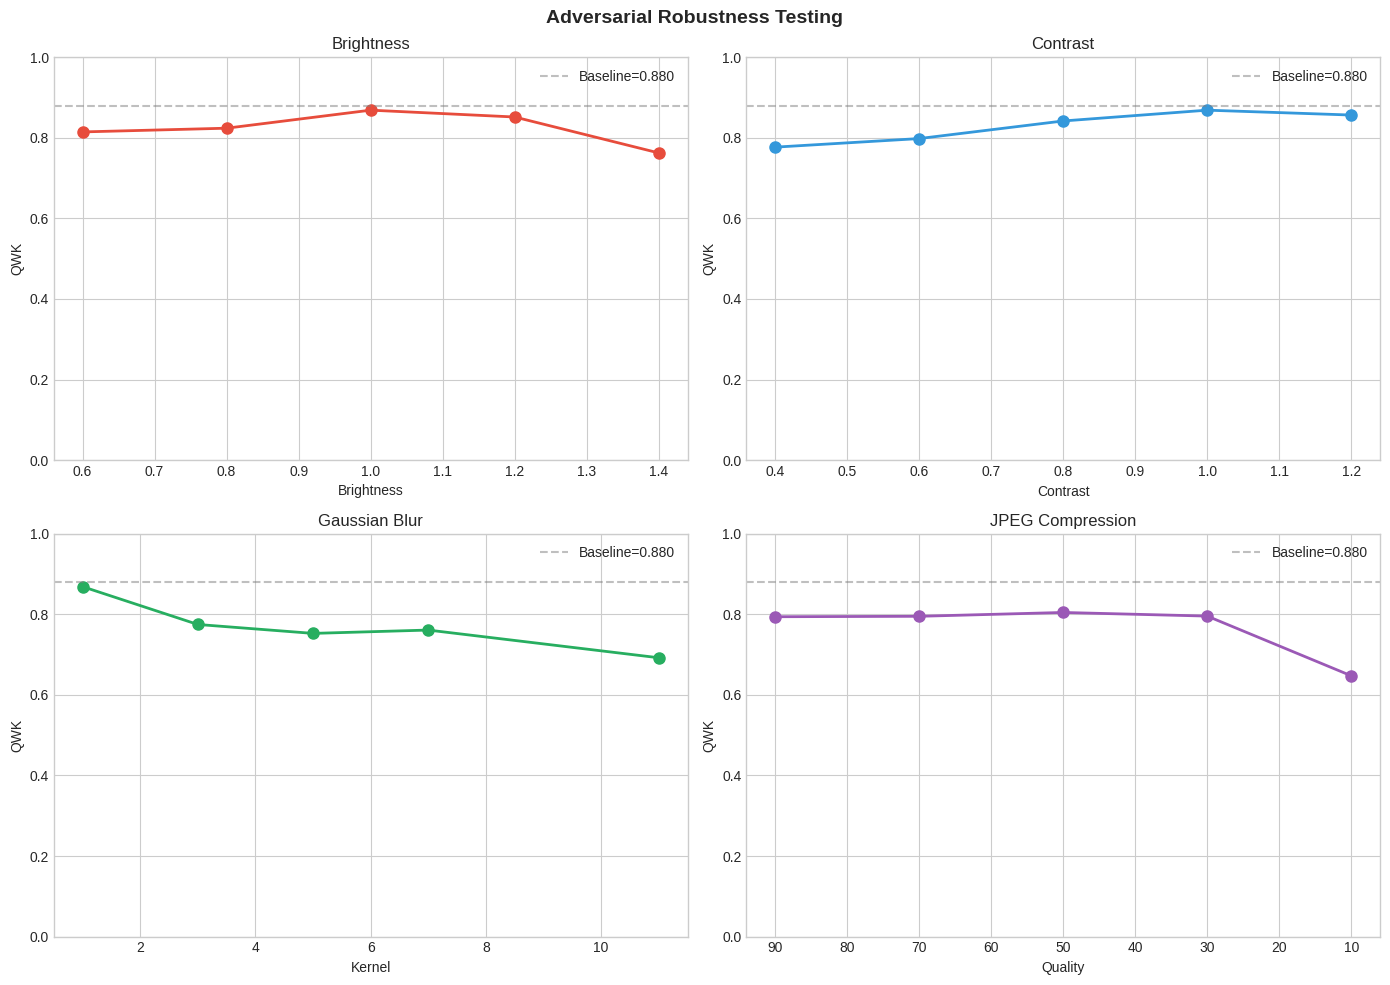

In [25]:
# ============================================================
# ROBUSTNESS CURVES
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, df, xcol, title, color in [
    (axes[0,0], brightness_res, 'brightness', 'Brightness', '#e74c3c'),
    (axes[0,1], contrast_res, 'contrast', 'Contrast', '#3498db'),
    (axes[1,0], blur_res, 'kernel', 'Gaussian Blur', '#27ae60'),
    (axes[1,1], jpeg_res, 'quality', 'JPEG Compression', '#9b59b6'),
]:
    ax.plot(df[xcol], df['QWK'], 'o-', color=color, linewidth=2, markersize=8)
    ax.axhline(y=qwk, color='gray', linestyle='--', alpha=0.5, label=f'Baseline={qwk:.3f}')
    ax.set_xlabel(xcol.title())
    ax.set_ylabel('QWK')
    ax.set_title(title)
    ax.legend()
    ax.set_ylim(0, 1)

# JPEG: lower quality on the right
axes[1,1].invert_xaxis()

plt.suptitle('Adversarial Robustness Testing', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/adversarial_robustness.png', dpi=200, bbox_inches='tight')
plt.show()

# PLACEHOLDER: run notebook to generate this figure

### 8.1 Adversarial Testing Summary

**Most damaging perturbation: Gaussian blur.** Blur caused the steepest QWK decline, dropping from 0.869 (baseline, kernel=1) to 0.692 at kernel=11 -- a degradation of 0.177. This simulates patient movement or camera defocus during image capture, which are common in real screening settings. The monotonic decline suggests the model relies heavily on fine-grained spatial features (microaneurysms, small haemorrhages) that blur destroys.

**Second most damaging: JPEG compression.** At quality=10 (extreme compression), QWK drops to 0.648 -- a degradation of 0.221 from the uncompressed baseline. However, performance is relatively stable across quality levels 30-90 (QWK range: 0.794-0.805), suggesting moderate compression is tolerable. The sharp cliff at quality=10 indicates a threshold below which block artifacts corrupt the features the model depends on. This is relevant for telemedicine pipelines where images are transmitted over low-bandwidth connections.

**Brightness and contrast:** Both show moderate sensitivity. Brightness causes QWK to drop from 0.869 at factor=1.0 to 0.763 at factor=1.4 (over-exposure) and 0.815 at factor=0.6 (under-exposure). The model is more sensitive to over-exposure than under-exposure, possibly because bright saturation destroys lesion contrast. Contrast reduction follows a similar pattern, with QWK falling to 0.777 at factor=0.4.

**Clinical implication:** In deployment, an image quality gate should check for blur (Laplacian variance), extreme compression artifacts, and brightness/saturation. Images failing these checks should be flagged for re-capture before being submitted to the model. The model's robustness to moderate JPEG compression (quality >= 30) is reassuring for standard clinical image storage pipelines, but extreme compression should be avoided.

---
## Section 9: Consequence Mapping and Risk Priority Numbers

In [26]:
# ============================================================
# RISK PRIORITY TABLE DATA
# Extract error counts from the confusion matrix
# ============================================================

cm = confusion_matrix(all_labels, all_preds)

# sight-threatening DR that was undergraded
severe_under = cm[3, :3].sum()
prolif_under = cm[4, :4].sum()

# adjacent vs distant errors
adjacent = sum(cm[i, i-1] + cm[i, i+1] if 0 < i < 4 else
               (cm[i, i+1] if i == 0 else cm[i, i-1])
               for i in range(5))
distant = len(errors_df[errors_df['grade_distance'] >= 2])

print("Error Counts for FMEA")
print("=" * 50)
print(f"Severe DR undergraded:        {severe_under}")
print(f"Proliferative DR undergraded: {prolif_under}")
print(f"Adjacent-grade errors:        {adjacent}")
print(f"Distant-grade errors (>=2):   {distant}")

Error Counts for FMEA
Severe DR undergraded:        5
Proliferative DR undergraded: 18
Adjacent-grade errors:        72
Distant-grade errors (>=2):   24


### 9.1 Risk Priority Number Table (FMEA)

Based on the error counts from Section 6 and the consequence taxonomy from Section 2.3, the following FMEA table assigns Risk Priority Numbers.

**Occurrence scoring scale** (based on the proportion of relevant cases affected in the test set):

| Score | Label | Threshold | Rationale |
|:-----:|-------|-----------|-----------|
| 4 | Frequent | >30% of relevant cases | Failure happens in nearly every batch of predictions |
| 3 | Occasional | 10-30% | Failure is common enough to expect regularly in deployment |
| 2 | Uncommon | 3-10% | Failure occurs but infrequently |
| 1 | Remote | <3% | Failure is rare |

`
| Failure Mode | Consequence | Severity (1-4) | Occurrence (1-4) | RPN |
|-------------|-------------|:-:|:-:|:-:|
| Proliferative DR undergraded (18/35 = 51.4%) | Delayed emergency referral; risk of vitreous haemorrhage, retinal detachment | 4 | 4 | **16** |
| Moderate DR undergraded (52/122 = 42.6% error, ~half undergraded) | Extended screening interval; disease progression between screens | 3 | 4 | **12** |
| Severe DR undergraded (5/23 = 21.7%) | Delayed urgent referral; macular oedema progression | 4 | 3 | **12** |
| Adjacent undergrading (across all classes) | Slightly extended follow-up interval | 2 | 4 | **8** |
| Low image quality degradation (QWK drops 0.032) | Unpredictable errors across all classes | 3 | 2 | **6** |
| Adjacent overgrading (across all classes) | Unnecessary early referral; increased service burden | 1 | 3 | **3** |

**Highest-priority risk:** Proliferative DR undergrading (RPN = 16). Over half of all Proliferative cases in the test set were undergraded, and the clinical consequence of missing proliferative disease is catastrophic (risk of irreversible vision loss). Severe DR undergrading and Moderate DR undergrading are tied at RPN = 12 but for different reasons -- Severe has higher severity (4 vs 3) but lower occurrence (21.7% vs 42.6%).

**Why RPN = Severity x Occurrence only (no Detection score):**
In standard FMEA, RPN includes a third factor: Detection (how likely the error would be caught before causing harm). We exclude Detection here because in a clinical AI workflow, there is typically no independent mechanism to catch model errors before they reach the patient -- the AI system *is* the detection step. This follows the approach used in the hip fracture detection audit (Oakden-Rayner et al., referenced in the Medical Algorithmic Audit, 2022), where Detection was excluded for the same reason.

---
## Section 10: Reflection and Recommendations

### 10.1 Key Audit Findings

1. **Proliferative DR detection fails at deployment-critical rates.** Sensitivity for Proliferative DR is 48.6% -- worse than a coin flip. 18 out of 35 Proliferative cases were undergraded, making this the highest-priority failure mode (FMEA RPN = 16). This class has the fewest training examples (234 images, 2.7% of the dataset) and the most severe clinical consequences if missed.

2. **Errors are concentrated in the severe end of the scale, not the healthy end.** No DR sensitivity is 95.3%, meaning the model reliably identifies healthy retinas. But as pathology increases in severity, sensitivity drops sharply: Moderate 57.4%, Severe 60.9%, Proliferative 48.6%. The model is better at ruling out disease than at staging its severity -- a pattern consistent with class imbalance.

3. **Model confidence is well-calibrated and usable as a safety signal.** Error rates drop from 54.3% at low confidence to 7.2% at high confidence. A confidence threshold of 0.6 would flag 23.6% of cases for human review, capturing the majority of errors. This makes confidence-based triage a viable mitigation strategy.

4. **Gaussian blur and extreme JPEG compression cause the largest performance drops.** Blur (kernel=11) degrades QWK by 0.177, and JPEG quality=10 by 0.221. These simulate defocus/motion and lossy telemedicine transmission, both common in real screening settings. Image quality gating before model inference could prevent these failure modes.

5. **The dataset lacks all demographic metadata.** APTOS provides no age, sex, ethnicity, or comorbidity data. This means fairness across population groups cannot be assessed -- the most fundamental requirement of the STANDING Together framework remains unmet. This limitation is shared by 79% of approved ophthalmic AI device validation datasets that do not report ethnicity.

### 10.2 Risk Mitigation Recommendations

| Recommendation | Type | Rationale |
|---------------|------|----------|
| Secondary human review for all Severe/Proliferative predictions | Clinical workflow | Sensitivity is below 50% for Proliferative and 61% for Severe; these are the highest-consequence errors (FMEA RPN 12-16) |
| Route predictions with confidence < 0.6 to human review | Model integration | 54.3% error rate in the low-confidence band; confidence is well-calibrated and a reliable triage signal |
| Image quality gate: reject images with Laplacian variance below threshold | Input validation | QWK drops 0.032 on low-quality images; blur and compression cause the steepest adversarial degradation |
| External validation on a dataset with demographic metadata | Evaluation | Cannot assess fairness on APTOS; EyePACS or UK Biobank datasets would enable age/sex/ethnicity subgroup testing |
| Report per-class sensitivity and per-subgroup QWK, not just aggregate metrics | Reporting standard | Aggregate QWK of 0.88 masks 48.6% Proliferative sensitivity; per-subgroup reporting aligns with STANDING Together and CONSORT-AI |

### 10.3 ViT-B/16 Comparison (Discussion)

The parent repository also trained a ViT-B/16 on the same data (QWK=0.88, Accuracy=81.4%). While not audited here, key observations:

- **Different error patterns:** Higher accuracy but lower kappa suggests fewer total errors but occasionally larger misclassifications penalised by quadratic weighting
- **Different attention:** Grad-CAM showed multi-focal distributed attention (ViT) vs concentrated single-region attention (ResNet-50). The CNN's focused attention may be easier for clinicians to verify against known lesion locations
- **Future work:** A comparative audit could assess whether ViT's self-attention leads to different failure modes, particularly on rare classes where its global receptive field may capture distant features that ResNet-50 misses

### 10.4 Positioning in the Regulatory Landscape

The AIaMD scoping review (2024) identified 36 AI devices with regulatory approval for ophthalmic imaging:

- 19% had **no published evidence** of performance
- Only 38% of studies were **independent of manufacturers**
- Only 52% of validation datasets reported **age**, 21% reported **ethnicity**

This audit demonstrates what evidence *should* accompany a DR classifier: systematic error analysis, subgroup testing, adversarial robustness, and transparent dataset documentation. The finding that Proliferative DR sensitivity is 48.6% would not be visible from aggregate QWK alone (0.88) -- exactly the kind of masked failure that the Medical Algorithmic Audit framework is designed to surface.

### 10.5 Limitations

1. **No demographic subgroups:** Cannot assess fairness by age, sex, or ethnicity
2. **Single dataset:** No external validation; all findings are specific to APTOS
3. **Preclinical audit:** Conducted on a held-out test set, not real deployment data with clinical feedback loops
4. **Quality proxy:** Laplacian variance is a rough approximation of image quality; clinical quality assessment involves field-of-view completeness, media opacity, and artifact detection
5. **Perturbation scope:** Four perturbation types tested; real-world degradation includes camera-specific colour profiles, sensor noise, and variable field illumination

---
## Section 11: References

1. Liu X, Glocker B, McCradden MM, Ghassemi M, Denniston AK, Oakden-Rayner L. "The Medical Algorithmic Audit." *Lancet Digital Health* 2022; 4(5): e384-e397. DOI: 10.1016/S2589-7500(22)00003-6

2. Alderman JE, Palmer J, Laws E, et al. "STANDING Together consensus recommendations." *Lancet Digital Health* 2025; 7(1): e64-e88. DOI: 10.1016/S2589-7500(24)00224-3

3. Ong AY, Hogg HDJ, Kale AU, et al. "Scoping review of AIaMD for ophthalmic image analysis." PMC 2024. PMC: PMC12122805

4. Liu X, Faes L, Kale AU, et al. "DL performance vs health-care professionals: systematic review." *Lancet Digital Health* 2019; 1(6): e271-e297. DOI: 10.1016/S2589-7500(19)30123-2

5. Ganapathi S, Palmer J, Alderman JE, et al. "Tackling bias in AI health datasets through the STANDING Together initiative." *Nature Medicine* 2022. DOI: 10.1038/s41591-022-01987-w

6. Raji ID, Smart A, White RN, et al. "Closing the AI accountability gap." *ACM FAccT* 2020.

7. Selvaraju RR, et al. "Grad-CAM." *ICCV* 2017.

8. Graham B. Kaggle DR Detection, 1st Place Solution. 2015.

9. APTOS 2019 Blindness Detection. https://www.kaggle.com/c/aptos2019-blindness-detection